In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import re
from bs4 import BeautifulSoup

import warnings
warnings.filterwarnings('ignore')

C:\Users\Admin\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
df = pd.read_csv('../train.csv')

In [3]:
new_df = df.sample(30000,random_state=2)

In [4]:
def preprocess(q):
    q = str(q).lower().strip()
    
    # Replace certain special characters with their string equivalents:
    q = q.replace('%', ' percent')
    q = q.replace('$', ' dollar ')
    q = q.replace('₹', ' rupee ')
    q = q.replace('€', ' euro ')
    q = q.replace('@', ' at ')


    # The pattern '[math]' appears around 900 times in the whole dataset.
    q = q.replace('[math]', '')

    # Replacing some numbers with string equivalents (not perfect, can be done better to account for more cases)
    q = q.replace(',000,000,000 ', 'b ')
    q = q.replace(',000,000 ', 'm ')
    q = q.replace(',000 ', 'k ')
    q = re.sub(r'([0-9]+)000000000', r'\1b', q)
    q = re.sub(r'([0-9]+)000000', r'\1m', q)
    q = re.sub(r'([0-9]+)000', r'\1k', q)

    # Decontracting words
    # https://en.wikipedia.org/wiki/Wikipedia%3aList_of_English_contractions
    # https://stackoverflow.com/a/19794953
    contractions = { 
    "ain't": "am not",
    "aren't": "are not",
    "can't": "can not",
    "can't've": "can not have",
    "'cause": "because",
    "could've": "could have",
    "couldn't": "could not",
    "couldn't've": "could not have",
    "didn't": "did not",
    "doesn't": "does not",
    "don't": "do not",
    "hadn't": "had not",
    "hadn't've": "had not have",
    "hasn't": "has not",
    "haven't": "have not",
    "he'd": "he would",
    "he'd've": "he would have",
    "he'll": "he will",
    "he'll've": "he will have",
    "he's": "he is",
    "how'd": "how did",
    "how'd'y": "how do you",
    "how'll": "how will",
    "how's": "how is",
    "i'd": "i would",
    "i'd've": "i would have",
    "i'll": "i will",
    "i'll've": "i will have",
    "i'm": "i am",
    "i've": "i have",
    "isn't": "is not",
    "it'd": "it would",
    "it'd've": "it would have",
    "it'll": "it will",
    "it'll've": "it will have",
    "it's": "it is",
    "let's": "let us",
    "ma'am": "madam",
    "mayn't": "may not",
    "might've": "might have",
    "mightn't": "might not",
    "mightn't've": "might not have",
    "must've": "must have",
    "mustn't": "must not",
    "mustn't've": "must not have",
    "needn't": "need not",
    "needn't've": "need not have",
    "o'clock": "of the clock",
    "oughtn't": "ought not",
    "oughtn't've": "ought not have",
    "shan't": "shall not",
    "sha'n't": "shall not",
    "shan't've": "shall not have",
    "she'd": "she would",
    "she'd've": "she would have",
    "she'll": "she will",
    "she'll've": "she will have",
    "she's": "she is",
    "should've": "should have",
    "shouldn't": "should not",
    "shouldn't've": "should not have",
    "so've": "so have",
    "so's": "so as",
    "that'd": "that would",
    "that'd've": "that would have",
    "that's": "that is",
    "there'd": "there would",
    "there'd've": "there would have",
    "there's": "there is",
    "they'd": "they would",
    "they'd've": "they would have",
    "they'll": "they will",
    "they'll've": "they will have",
    "they're": "they are",
    "they've": "they have",
    "to've": "to have",
    "wasn't": "was not",
    "we'd": "we would",
    "we'd've": "we would have",
    "we'll": "we will",
    "we'll've": "we will have",
    "we're": "we are",
    "we've": "we have",
    "weren't": "were not",
    "what'll": "what will",
    "what'll've": "what will have",
    "what're": "what are",
    "what's": "what is",
    "what've": "what have",
    "when's": "when is",
    "when've": "when have",
    "where'd": "where did",
    "where's": "where is",
    "where've": "where have",
    "who'll": "who will",
    "who'll've": "who will have",
    "who's": "who is",
    "who've": "who have",
    "why's": "why is",
    "why've": "why have",
    "will've": "will have",
    "won't": "will not",
    "won't've": "will not have",
    "would've": "would have",
    "wouldn't": "would not",
    "wouldn't've": "would not have",
    "y'all": "you all",
    "y'all'd": "you all would",
    "y'all'd've": "you all would have",
    "y'all're": "you all are",
    "y'all've": "you all have",
    "you'd": "you would",
    "you'd've": "you would have",
    "you'll": "you will",
    "you'll've": "you will have",
    "you're": "you are",
    "you've": "you have"
    }


    q_decontracted = []

    for word in q.split():
        if word in contractions:
            word = contractions[word]

        q_decontracted.append(word)

    q = ' '.join(q_decontracted)
    q = q.replace("'ve", " have")
    q = q.replace("n't", " not")
    q = q.replace("'re", " are")
    q = q.replace("'ll", " will")
    
    # Removing HTML tags
    q = BeautifulSoup(q)
    q = q.get_text()
    
    # Remove punctuations
    pattern = re.compile('\W')
    q = re.sub(pattern, ' ', q).strip()

   # remove all kinds of whitespace
    q = re.sub(r'\s+', ' ', q).strip()
    
    return q

In [5]:
# apply the preprocess function on dataset 

new_df['question1'] = new_df['question1'].apply(preprocess)
new_df['question2'] = new_df['question2'].apply(preprocess)

In [6]:
# Create a new columns 'q1_len', q2_len char lenth of q1 and q2

new_df['q1_len'] = new_df['question1'].str.len() 
new_df['q2_len'] = new_df['question2'].str.len()

In [7]:
# create a new column of 'q1_num_words'  words in q1

new_df['q1_num_words'] = new_df['question1'].apply(lambda row: len(row.split(" ")))
new_df['q2_num_words'] = new_df['question2'].apply(lambda row: len(row.split(" ")))
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words
398782,398782,496695,532029,what is the best marketing automation tool for...,what is the best marketing automation tool for...,1,75,76,13,13
115086,115086,187729,187730,i am poor but i want to invest what should i do,i am quite poor and i want to be very rich wha...,0,47,55,12,15
327711,327711,454161,454162,i am from india and live abroad i met a guy fr...,t i e t to thapar university to thapar univers...,0,102,118,26,20
367788,367788,498109,491396,why do so many people in the u s hate the sout...,my boyfriend doesnt feel guilty when he hurts ...,0,57,143,13,30
151235,151235,237843,50930,consequences of bhopal gas tragedy,what was the reason behind the bhopal gas tragedy,0,34,49,5,9


In [8]:
def common_words(row):
    w1 = set(map(lambda word: word.lower().strip(), row['question1'].split(" ")))
    w2 = set(map(lambda word: word.lower().strip(), row['question2'].split(" ")))    
    return len(w1 & w2)

In [9]:
new_df['word_common'] = new_df.apply(common_words, axis=1)
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common
398782,398782,496695,532029,what is the best marketing automation tool for...,what is the best marketing automation tool for...,1,75,76,13,13,12
115086,115086,187729,187730,i am poor but i want to invest what should i do,i am quite poor and i want to be very rich wha...,0,47,55,12,15,7
327711,327711,454161,454162,i am from india and live abroad i met a guy fr...,t i e t to thapar university to thapar univers...,0,102,118,26,20,3
367788,367788,498109,491396,why do so many people in the u s hate the sout...,my boyfriend doesnt feel guilty when he hurts ...,0,57,143,13,30,0
151235,151235,237843,50930,consequences of bhopal gas tragedy,what was the reason behind the bhopal gas tragedy,0,34,49,5,9,3


In [10]:
def total_words(row):
    w1 = set(map(lambda word: word.lower().strip(), row['question1'].split(" ")))
    w2 = set(map(lambda word: word.lower().strip(), row['question2'].split(" ")))    
    return (len(w1) + len(w2))

In [11]:
new_df['word_total'] = new_df.apply(total_words, axis=1)
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total
398782,398782,496695,532029,what is the best marketing automation tool for...,what is the best marketing automation tool for...,1,75,76,13,13,12,26
115086,115086,187729,187730,i am poor but i want to invest what should i do,i am quite poor and i want to be very rich wha...,0,47,55,12,15,7,22
327711,327711,454161,454162,i am from india and live abroad i met a guy fr...,t i e t to thapar university to thapar univers...,0,102,118,26,20,3,36
367788,367788,498109,491396,why do so many people in the u s hate the sout...,my boyfriend doesnt feel guilty when he hurts ...,0,57,143,13,30,0,32
151235,151235,237843,50930,consequences of bhopal gas tragedy,what was the reason behind the bhopal gas tragedy,0,34,49,5,9,3,13


In [12]:
new_df['word_share'] = round(new_df['word_common']/new_df['word_total'],2)
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share
398782,398782,496695,532029,what is the best marketing automation tool for...,what is the best marketing automation tool for...,1,75,76,13,13,12,26,0.46
115086,115086,187729,187730,i am poor but i want to invest what should i do,i am quite poor and i want to be very rich wha...,0,47,55,12,15,7,22,0.32
327711,327711,454161,454162,i am from india and live abroad i met a guy fr...,t i e t to thapar university to thapar univers...,0,102,118,26,20,3,36,0.08
367788,367788,498109,491396,why do so many people in the u s hate the sout...,my boyfriend doesnt feel guilty when he hurts ...,0,57,143,13,30,0,32,0.00
151235,151235,237843,50930,consequences of bhopal gas tragedy,what was the reason behind the bhopal gas tragedy,0,34,49,5,9,3,13,0.23


# Advanced Features

In [13]:
import nltk

# nltk.download('stopwords')

In [14]:
import nltk
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))
print(stop_words)

{'off', "hasn't", 'before', 'the', 'needn', 'shan', 'shouldn', 'did', 'why', "he's", 'being', 'not', 'down', 'of', 'such', 'yours', 'again', 'itself', 'then', "shan't", 'our', 'up', 'so', 'her', 'because', 'only', 't', 'do', 'further', 'me', "mustn't", "she's", 'and', "shouldn't", 'we', 'about', 'don', 'hadn', 'ma', 'is', "you're", 'wasn', 'this', 'ourselves', 'be', 'themselves', 'were', "aren't", "she'll", 'm', 've', "they'll", 'my', 'when', 'whom', 'their', 'aren', 'from', 'myself', 'she', 'd', 'same', "wouldn't", 'own', 'himself', 'hasn', 'yourselves', "it's", 'out', "haven't", 'doing', 'herself', 'o', "don't", "it'll", 'having', 'nor', 'will', "they've", "mightn't", 'there', 'wouldn', 'it', "they'd", 'more', 'been', 'few', 'its', "won't", 'at', 'll', 'that', "hadn't", "we've", 'but', 'which', "you'd", "we'd", 'most', 'should', "she'd", 'very', 'i', 'no', 'he', "it'd", 'are', 'in', "i'm", 'his', 'just', 'has', 'until', "we're", "i'll", 'each', 'mustn', 'doesn', 'once', 'theirs', "we

In [15]:
# Advanced Features
from nltk.corpus import stopwords

def fetch_token_features(row):
    
    q1 = row['question1']
    q2 = row['question2']
    
    SAFE_DIV = 0.0001 

    STOP_WORDS = stopwords.words("english")
    
    token_features = [0.0]*8
    
    # Converting the Sentence into Tokens: 
    q1_tokens = q1.split()
    q2_tokens = q2.split()
    
    if len(q1_tokens) == 0 or len(q2_tokens) == 0:
        return token_features

    # Get the non-stopwords in Questions
    q1_words = set([word for word in q1_tokens if word not in STOP_WORDS])
    q2_words = set([word for word in q2_tokens if word not in STOP_WORDS])

    # get the stopwords in questions:
    q1_stops = set([word for word in q1_tokens if word in STOP_WORDS])
    q2_stops = set([word for word in q2_tokens if word in STOP_WORDS])

    # Get the common non-stopwords from question pair
    common_word_count = len(q1_words.intersection(q2_words))

    # Get the common stopwords from question pair
    common_stop_count = len(q1_stops.intersection(q2_stops))

    # Get the common tokens from question pair
    common_token_count = len(set(q1_tokens).intersection(set(q2_tokens)))


    token_features[0] = common_word_count / (min(len(q1_words), len(q2_words)) + SAFE_DIV)
    token_features[1] = common_word_count / (max(len(q1_words), len(q2_words)) + SAFE_DIV)
    token_features[2] = common_stop_count / (min(len(q1_stops), len(q2_stops)) + SAFE_DIV)
    token_features[3] = common_stop_count / (max(len(q1_stops), len(q2_stops)) + SAFE_DIV)
    token_features[4] = common_token_count / (min(len(q1_tokens), len(q2_tokens)) + SAFE_DIV)
    token_features[5] = common_token_count / (max(len(q1_tokens), len(q2_tokens)) + SAFE_DIV)

    # Last word of both question is same or not
    token_features[6] = int(q1_tokens[-1] == q2_tokens[-1])

    # First word of both question is same or not
    token_features[7] = int(q1_tokens[0] == q2_tokens[0])

    return token_features
    

In [16]:
token_features = new_df.apply(fetch_token_features, axis = 1)

In [17]:
new_df['cwc_min'] = list(map(lambda x: x[0], token_features))
new_df['cwc_max'] = list(map(lambda x: x[1], token_features))
new_df['csc_min'] = list(map(lambda x: x[2], token_features))
new_df['csc_max'] = list(map(lambda x: x[3], token_features))
new_df['ctc_min'] = list(map(lambda x: x[4], token_features))
new_df['ctc_max'] = list(map(lambda x: x[5], token_features))
new_df['last_word_eq'] = list(map(lambda x: x[6], token_features))
new_df['first_word_eq'] = list(map(lambda x: x[7], token_features))

# Length Based Features

In [18]:
# Length Based Features
import distance

def fetch_length_features(row):
    q1 = row['question1']
    q2 = row['question2']

    length_features = [0.0]*3

    # Converting the sentance into tokens:
    q1_tokens = q1.split()
    q2_tokens = q2.split()

    if len(q1_tokens) == 0 or len(q2_tokens) == 0:
        return length_features

    # Absolute length features
    length_features[0] = abs(len(q1_tokens) - len(q2_tokens))

    # Average Token Length of both Questions   
    length_features[1] = (len(q1_tokens) + len(q2_tokens))/2

    strs = list(distance.lcsubstrings(q1, q2))
    length_features[2] = len(strs[0]) / (min(len(q1), len(q2)) + 1)

    return length_features


In [19]:
length_features = new_df.apply(fetch_length_features, axis=1)

new_df['abs_len_diff'] = list(map(lambda x: x[0], length_features))
new_df['mean_len'] = list(map(lambda x: x[1], length_features))
new_df['longest_substr_ratio'] = list(map(lambda x: x[2], length_features))

# Fuzzy Features

In [20]:
# Fuzzy Features

from fuzzywuzzy import fuzz

def fetch_fuzzy_features(row):
    q1 = row['question1']
    q2 = row['question2']

    fuzzy_features = [0.0]*4

    # fuzz_ratio
    fuzzy_features[0] = fuzz.QRatio(q1, q2)  # Usage: This provides a similarity score by performing an exact character-by-character comparison of the two strings (case-sensitive).

    # fuzz_partial_ratio
    fuzzy_features[1] = fuzz.partial_ratio(q1, q2)   # Use: Yeh substring matching ke liye hota hai. Agar ek string choti hai aur wo badi string ke andar kahi bhi milti hai, toh yeh high score deta hai.


 # Use: Yeh words ko alphabetical order mein sort karke compare karta hai. Isse farq nahi padta ki words aage-piche likhe hain ya nahi (jaise "machine learning" aur "learning machine").
    # token_sort_ratio
    fuzzy_features[2] = fuzz.token_sort_ratio(q1, q2)   


# Usage: It ignores duplicate words and matches overlapping words without regard to order.
    # token_set_ratio
    fuzzy_features[3] = fuzz.token_set_ratio(q1, q2)  


    return fuzzy_features


In [21]:
fuzzy_features = new_df.apply(fetch_fuzzy_features, axis=1)

# Creating new feature columns for fuzzy features
new_df['fuzz_ratio'] = list(map(lambda x: x[0], fuzzy_features))
new_df['fuzz_partial_ratio'] = list(map(lambda x: x[1], fuzzy_features))
new_df['token_sort_ratio'] = list(map(lambda x: x[2], fuzzy_features))
new_df['token_set_ratio'] = list(map(lambda x: x[3], fuzzy_features))

In [22]:
new_df.shape

(30000, 28)

In [23]:
new_df.columns

Index(['id', 'qid1', 'qid2', 'question1', 'question2', 'is_duplicate',
       'q1_len', 'q2_len', 'q1_num_words', 'q2_num_words', 'word_common',
       'word_total', 'word_share', 'cwc_min', 'cwc_max', 'csc_min', 'csc_max',
       'ctc_min', 'ctc_max', 'last_word_eq', 'first_word_eq', 'abs_len_diff',
       'mean_len', 'longest_substr_ratio', 'fuzz_ratio', 'fuzz_partial_ratio',
       'token_sort_ratio', 'token_set_ratio'],
      dtype='str')

# Perform EDA on new columns 

In [24]:
ques_df = new_df[['question1','question2']]
ques_df.head()

,question1,question2
398782,what is the best marketing automation tool for...,what is the best marketing automation tool for...
115086,i am poor but i want to invest what should i do,i am quite poor and i want to be very rich wha...
327711,i am from india and live abroad i met a guy fr...,t i e t to thapar university to thapar univers...
367788,why do so many people in the u s hate the sout...,my boyfriend doesnt feel guilty when he hurts ...
151235,consequences of bhopal gas tragedy,what was the reason behind the bhopal gas tragedy


In [25]:
final_df = new_df.drop(columns=['id','qid1','qid2','question1','question2'])
print(final_df.shape)
final_df.head()

(30000, 23)


,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share,cwc_min,cwc_max,...,ctc_max,last_word_eq,first_word_eq,abs_len_diff,mean_len,longest_substr_ratio,fuzz_ratio,fuzz_partial_ratio,token_sort_ratio,token_set_ratio
398782,1,75,76,13,13,12,26,0.46,0.874989,0.874989,...,0.923070,1.0,1.0,0.0,13.0,0.855263,99,99,99,99
115086,0,47,55,12,15,7,22,0.32,0.666644,0.499988,...,0.466664,1.0,1.0,3.0,13.5,0.229167,69,66,65,74
327711,0,102,118,26,20,3,36,0.08,0.000000,0.000000,...,0.115384,0.0,0.0,6.0,23.0,0.048544,26,30,34,43
367788,0,57,143,13,30,0,32,0.00,0.000000,0.000000,...,0.000000,0.0,0.0,17.0,21.5,0.051724,27,46,23,30
151235,0,34,49,5,9,3,13,0.23,0.749981,0.599988,...,0.333330,1.0,0.0,4.0,7.0,0.542857,55,70,48,69


In [26]:
final_df.columns

Index(['is_duplicate', 'q1_len', 'q2_len', 'q1_num_words', 'q2_num_words',
       'word_common', 'word_total', 'word_share', 'cwc_min', 'cwc_max',
       'csc_min', 'csc_max', 'ctc_min', 'ctc_max', 'last_word_eq',
       'first_word_eq', 'abs_len_diff', 'mean_len', 'longest_substr_ratio',
       'fuzz_ratio', 'fuzz_partial_ratio', 'token_sort_ratio',
       'token_set_ratio'],
      dtype='str')

# from sklearn.feature_extraction.text import CountVectorizer
# merge texts
questions = list(ques_df['question1']) + list(ques_df['question2'])

cv = CountVectorizer(max_features=3000)
q1_arr, q2_arr = np.vsplit(cv.fit_transform(questions).toarray(),2)


In [27]:
import numpy as np
from gensim.models import Word2Vec

# Select questions
ques_df = new_df[['question1', 'question2']].copy()


# 1. Tokenization

questions = list(ques_df['question1']) + list(ques_df['question2'])

tokenized_questions = [question.lower().split() for question in questions]

# 2. Train Word2Vec

w2v_model = Word2Vec(
    sentences=tokenized_questions,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1
)

# 3. Convert each question into a vector

def question_to_vector(question, model):

    words = question.lower().split()

    vectors = [model.wv[word] for word in words if word in model.wv]

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)



# 4. Create vectors for all questions

question_vectors = np.array([question_to_vector(question, w2v_model) for question in questions])


# 5. Split Q1 and Q2

q1_arr, q2_arr = np.vsplit(question_vectors, 2)

print("Q1 shape:", q1_arr.shape)
print("Q2 shape:", q2_arr.shape)


Q1 shape: (30000, 100)
Q2 shape: (30000, 100)


In [28]:
temp_df1 = pd.DataFrame(q1_arr, index= ques_df.index)
temp_df2 = pd.DataFrame(q2_arr, index= ques_df.index)
temp_df = pd.concat([temp_df1, temp_df2], axis=1)
temp_df.shape

(30000, 200)

In [29]:
final_df = pd.concat([final_df, temp_df], axis=1)
print(final_df.shape)
final_df.head()

(30000, 223)


,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share,cwc_min,cwc_max,...,90,91,92,93,94,95,96,97,98,99
398782,1,75,76,13,13,12,26,0.46,0.874989,0.874989,...,0.293695,0.153664,0.018884,0.155262,0.204484,0.100420,-0.021558,-0.076438,0.032968,0.185184
115086,0,47,55,12,15,7,22,0.32,0.666644,0.499988,...,0.217014,-0.042729,0.046631,0.009644,0.584990,-0.070917,0.114444,-0.073554,-0.091545,-0.166199
327711,0,102,118,26,20,3,36,0.08,0.000000,0.000000,...,0.274027,0.067653,0.112638,-0.040870,0.356881,0.007459,0.200772,-0.191411,0.036936,-0.124132
367788,0,57,143,13,30,0,32,0.00,0.000000,0.000000,...,0.348039,-0.068017,-0.062059,0.004286,0.503164,0.148581,0.183537,-0.189762,-0.073731,-0.045905
151235,0,34,49,5,9,3,13,0.23,0.749981,0.599988,...,0.417252,-0.016290,0.029904,0.243813,0.231969,0.134840,0.067628,-0.001023,0.059266,0.165762


In [49]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(final_df.iloc[:,1:].values,final_df.iloc[:,0].values,test_size=0.2,random_state=1)

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

# support vector machine

In [32]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# model object
svc = SVC(max_iter = 100, kernel='rbf', C =1)
svc.fit(X_train_sc, y_train)
# prediction
y_pred = svc.predict(X_test_sc)

# accuray score
accuracy = accuracy_score(y_pred, y_test)
print("Accuracy score = ", accuracy)

# confusion matrix
conf = confusion_matrix(y_pred, y_test)
print(conf)

# classification
clas = classification_report(y_pred, y_test)
print(clas)

Accuracy score =  0.6235
[[3422 1869]
 [ 390  319]]
              precision    recall  f1-score   support

           0       0.90      0.65      0.75      5291
           1       0.15      0.45      0.22       709

    accuracy                           0.62      6000
   macro avg       0.52      0.55      0.49      6000
weighted avg       0.81      0.62      0.69      6000



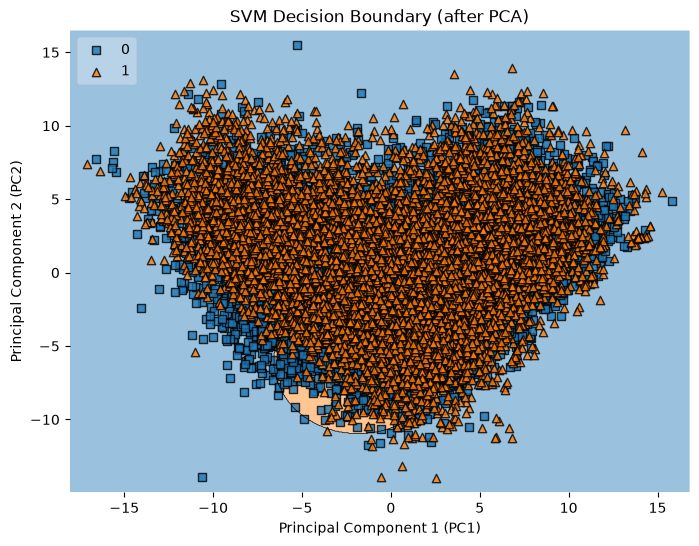

In [33]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from mlxtend.plotting import plot_decision_regions

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train_sc)

# model object
svc = SVC(max_iter = 100, kernel='rbf', C =1)
svc.fit(X_pca, y_train)

plt.figure(figsize=(8, 6))
plot_decision_regions(X_pca, y_train, clf=svc, legend=2)

# Graph ki styling
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.title('SVM Decision Boundary (after PCA)')
plt.show()


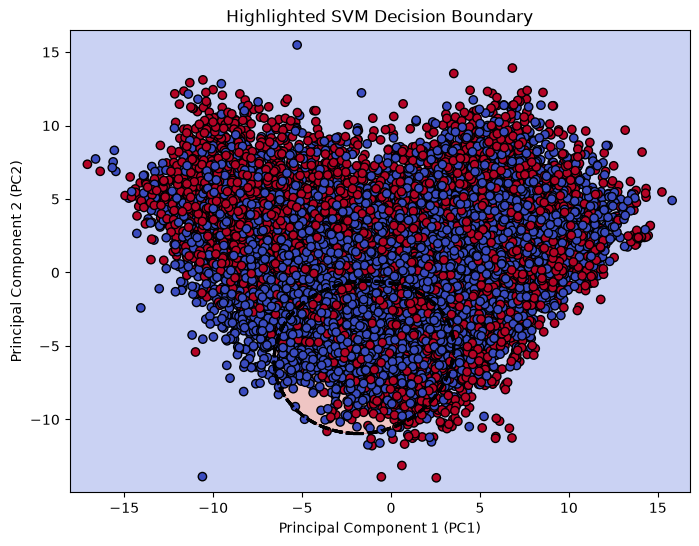

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC

# 1. Model train kar chuke hain (svc aur X_pca ready hain)
# 2. Plotting ke liye grid points banate hain
x_min, x_max = X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1
y_min, y_max = X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

# 3. Grid ke har point par model ka prediction nikalte hain
Z = svc.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))

# 4. Background regions plot karein
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)

# **5. Main Decision Boundary ko Highlight karne ke liye Contour line draw karein**
plt.contour(xx, yy, Z, colors='black', linewidths=2, linestyles='--') # <-- Yeh line boundary ko highlight karegi!

# 6. Data points plot karein
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_train, cmap=plt.cm.coolwarm, edgecolors='k')

plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.title('Highlighted SVM Decision Boundary')
plt.show()

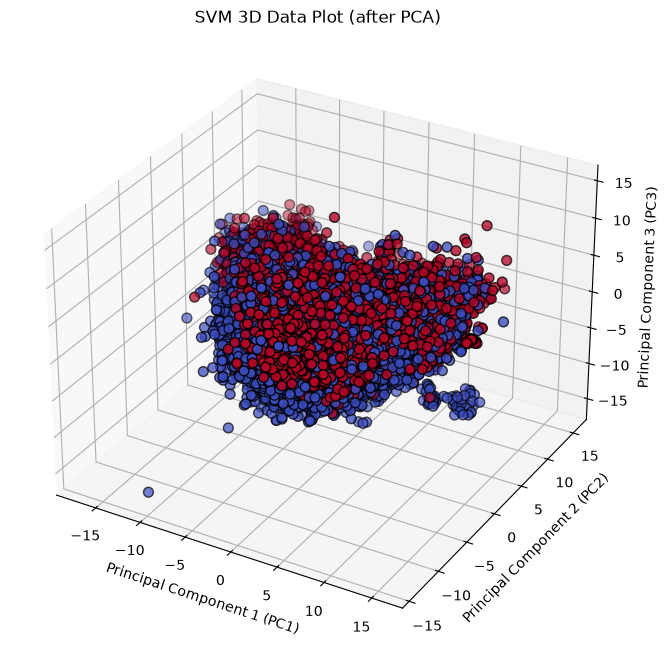

In [35]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from sklearn.svm import SVC

# 1. PCA ko 3 components mein set karein (3D data ke liye)
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_train_sc)

# 2. Model object train karein 3D data par
svc = SVC(max_iter=100, kernel='rbf', C=1)
svc.fit(X_pca, y_train)

# 3. 3D Figure aur Axis setup karein
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection='3d')

# 4. Data points ko 3D scatter plot mein plot karein
# c=y_train se classes alag-alag colors mein dikhengi
scatter = ax.scatter(
    X_pca[:, 0], # PC1
    X_pca[:, 1], # PC2
    X_pca[:, 2], # PC3
    c=y_train, 
    cmap=plt.cm.coolwarm, 
    edgecolor='k', 
    s=50
)

# 5. Graph ki styling aur Labels
ax.set_xlabel('Principal Component 1 (PC1)')
ax.set_ylabel('Principal Component 2 (PC2)')
ax.set_zlabel('Principal Component 3 (PC3)')
ax.set_title('SVM 3D Data Plot (after PCA)')

plt.show()

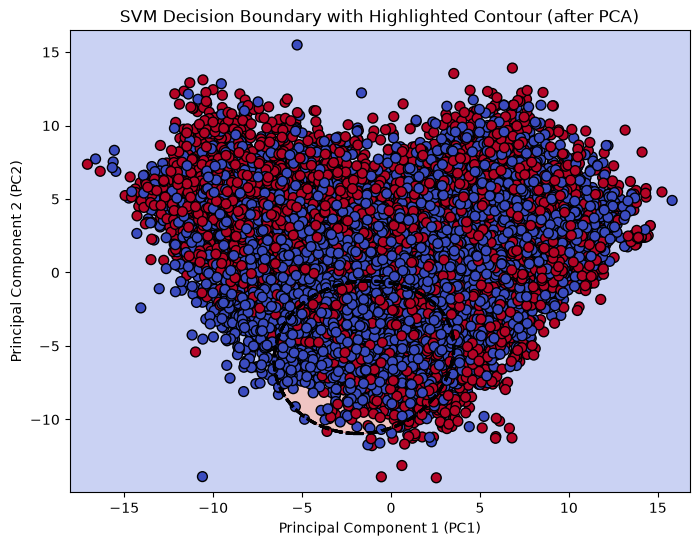

In [36]:
import numpy as np
import matplotlib.pyplot as plt  
from sklearn.decomposition import PCA
from sklearn.svm import SVC

# 1. PCA ko 2 components par set karein (2D plotting ke liye)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train_sc)

# 2. Model object ko 2D data par train karein
svc = SVC(max_iter=100, kernel='rbf', C=1)
svc.fit(X_pca, y_train)

# 3. Plotting ke liye grid points banate hain
x_min, x_max = X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1
y_min, y_max = X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

# 4. Grid ke har point par model ka prediction nikalte hain
Z = svc.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# 5. Graph plot karna shuru karein
plt.figure(figsize=(8, 6))

# Background regions plot karein (Shading)
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)

# Main Decision Boundary ko dark dashed line se highlight karein
plt.contour(xx, yy, Z, colors='black', linewidths=2, linestyles='--')

# 6. Actual Data points ko scatter plot par dikhayein
plt.scatter(
    X_pca[:, 0], 
    X_pca[:, 1], 
    c=y_train, 
    cmap=plt.cm.coolwarm, 
    edgecolors='k', 
    s=50
)

# Graph ki styling aur Labels
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.title('SVM Decision Boundary with Highlighted Contour (after PCA)')
plt.show()

In [48]:
svc.get_params()

{'break_ties': False,
 'cache_size': 200,
 'class_weight': None,
 'coef0': 0.0,
 'decision_function_shape': 'ovr',
 'degree': 3,
 'gamma': 'scale',
 'kernel': 'rbf',
 'max_iter': 100,
 'nu': 0.2,
 'probability': 'deprecated',
 'random_state': None,
 'shrinking': True,
 'tol': 0.001,
 'verbose': False}

In [52]:
from sklearn.svm import NuSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler,MinMaxScaler

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test) 


# model object
svc = NuSVC(max_iter = 100, kernel='rbf', nu =0.2)
svc.fit(X_train_sc, y_train)
# prediction
y_pred = svc.predict(X_test_sc)

# accuray score
accuracy = accuracy_score(y_pred, y_test)
print("Accuracy score = ", accuracy)

# confusion matrix
conf = confusion_matrix(y_pred, y_test)
print(conf)

# classification
clas = classification_report(y_pred, y_test)
print(clas)

Accuracy score =  0.7108333333333333
[[2773  696]
 [1039 1492]]
              precision    recall  f1-score   support

           0       0.73      0.80      0.76      3469
           1       0.68      0.59      0.63      2531

    accuracy                           0.71      6000
   macro avg       0.70      0.69      0.70      6000
weighted avg       0.71      0.71      0.71      6000



In [53]:
# check the Bias and Variance

# Training accuracy
y_train_pred = svc.predict(X_train_sc)
train_acc = accuracy_score(y_train, y_train_pred)

# Testing accuracy
y_test_pred = svc.predict(X_test_sc)
test_acc = accuracy_score(y_test, y_test_pred)

print("Training Accuracy:", train_acc)
print("Testing Accuracy:", test_acc)
print("Accuracy Gap:", train_acc - test_acc)

Training Accuracy: 0.7109583333333334
Testing Accuracy: 0.7108333333333333
Accuracy Gap: 0.00012500000000004174


In [39]:
svc.get_params()

{'break_ties': False,
 'cache_size': 200,
 'class_weight': None,
 'coef0': 0.0,
 'decision_function_shape': 'ovr',
 'degree': 3,
 'gamma': 'scale',
 'kernel': 'rbf',
 'max_iter': 100,
 'nu': 0.2,
 'probability': 'deprecated',
 'random_state': None,
 'shrinking': True,
 'tol': 0.001,
 'verbose': False}

In [40]:
# Support vectors per class
print(svc.n_support_)

# Total support vectors
print("Total support vectors:", svc.n_support_.sum())

# Percentage of training samples that are support vectors
percentage = (svc.n_support_.sum() / len(X_train_sc)) * 100

print("Support vector percentage:", percentage, "%")

[2400 2400]
Total support vectors: 4800
Support vector percentage: 20.0 %


### Precision:
Matlab: Jab model ne bola ki yeh '0' hai, toh kitni baar sach mein '0' tha?

### Recall:
Matlab: Jitne total asli '0' the, unmein se model ne kitne percent pakad liye?

### F1-Score
Simple Definition: F1-Score, Precision aur Recall ka Harmonic Mean (ek special average) hota hai.
Balance banana: Yeh dono metrics ko balance karta hai. Agar kisi model ki Precision bohot high hai 
lekin Recall bilkul zero hai, toh F1-Score bhi kharab (low) hi aayega. Model ko achha F1-score tabhi 
milega jab Precision aur Recall dono achhe honge.

In [41]:
svc.get_params()

{'break_ties': False,
 'cache_size': 200,
 'class_weight': None,
 'coef0': 0.0,
 'decision_function_shape': 'ovr',
 'degree': 3,
 'gamma': 'scale',
 'kernel': 'rbf',
 'max_iter': 100,
 'nu': 0.2,
 'probability': 'deprecated',
 'random_state': None,
 'shrinking': True,
 'tol': 0.001,
 'verbose': False}

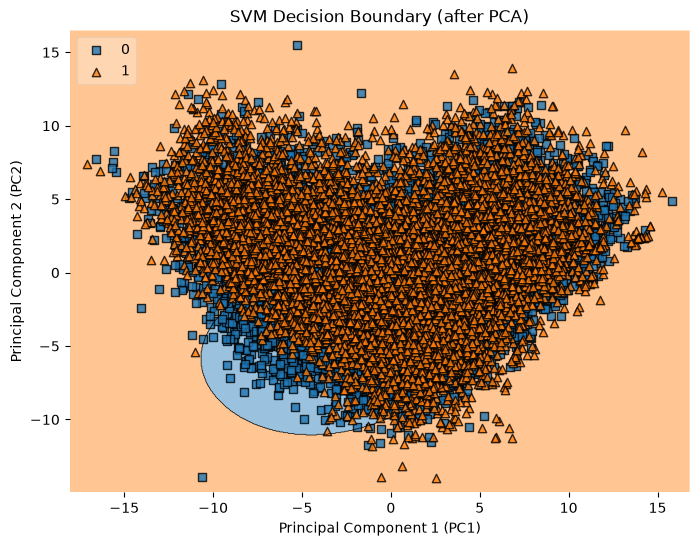

In [42]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.svm import NuSVC
from mlxtend.plotting import plot_decision_regions

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train_sc)

# model object
svc = NuSVC(max_iter = 100, kernel='rbf', nu =0.1)
svc.fit(X_pca, y_train)

plt.figure(figsize=(8, 6))
plot_decision_regions(X_pca, y_train, clf=svc, legend=2)

# Graph ki styling
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.title('SVM Decision Boundary (after PCA)')
plt.show()


In [43]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import NuSVC

# 1. Model train kar chuke hain (svc aur X_pca ready hain)
# 2. Plotting ke liye grid points banate hain
x_min, x_max = X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1
y_min, y_max = X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

# 3. Grid ke har point par model ka prediction nikalte hain
Z = svc.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))

# 4. Background regions plot karein
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)

# **5. Main Decision Boundary ko Highlight karne ke liye Contour line draw karein**
plt.contour(xx, yy, Z, colors='black', linewidths=2, linestyles='--') # <-- Yeh line boundary ko highlight karegi!

# 6. Data points plot karein
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_train, cmap=plt.cm.coolwarm, edgecolors='k')

plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.title('Highlighted SVM Decision Boundary')
plt.show()

KeyboardInterrupt: 

In [46]:
from sklearn.svm import NuSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Model object banayein aur train karein
svc = NuSVC(max_iter=100, kernel='rbf', nu=0.2, probability=True)
svc.fit(X_train_sc, y_train)

# 2. Final class predictions ke liye .predict() use karein
y_pred = svc.predict(X_test_sc)

# 3. Agar probabilities bhi dekhni hain, toh unhe alag variable mein rakhein
y_prob = svc.predict_proba(X_test_sc)
print("First 5 Probabilities:\n", y_prob[:5])
print("-" * 40)

# 4. Accuracy score (y_test pehle, y_pred baad mein)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy score =", accuracy)

# 5. Confusion matrix (Sahi syntax: y_true, y_pred)
conf = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", conf)

# 6. Classification report
clas = classification_report(y_test, y_pred)
print("Classification Report:\n", clas)

First 5 Probabilities:
 [[0.5783226  0.4216774 ]
 [0.59327349 0.40672651]
 [0.54287662 0.45712338]
 [0.54399358 0.45600642]
 [0.7043626  0.2956374 ]]
----------------------------------------
Accuracy score = 0.7108333333333333
Confusion Matrix:
 [[2773 1039]
 [ 696 1492]]
Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.73      0.76      3812
           1       0.59      0.68      0.63      2188

    accuracy                           0.71      6000
   macro avg       0.69      0.70      0.70      6000
weighted avg       0.72      0.71      0.71      6000



In [ ]:
print(s)

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from mlxtend.plotting import plot_decision_regions

# 1. Dataset load kiya (Iris dataset me 4 features hote hain)
iris = load_iris()
X = iris.data
y = iris.target

# 2. PCA ka use karke 4 features ko 2 features (components) me reduce kiya
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# 3. Logistic Regression model train kiya 2D data par
svc = SVC(kernel = 'linear')
svc.fit(X_pca, y)

# 4. MLxtend se Decision Boundary plot ki
plt.figure(figsize=(8, 6))
plot_decision_regions(X_pca, y, clf=svc, legend=2)

# Graph ki styling
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.title('SVC Decision Boundary (after PCA)')
plt.show()



In [ ]:
svc.get_params()